# VLM and Goal-Directed Attention


This notebook analyzes the attention-readout arm for both Qwen and Gemma. It mirrors `01_output_crossover.ipynb`, but computes correlations from saved `data/<run>/attn_maps_<run>/` grids instead of model answer coordinates.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import sys, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import pingouin as pg
from scipy import stats
import seaborn as sns

# analysis/ is the parent of notebooks/ — put it on the path so `helpers` imports.
ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))
from helpers import runs as R, util as U
from helpers import gaze_metrics as gm

print("data dir:", R.DATA_DIR)
MODELS = ["qwen-thinking", "gemma"]

data dir: /path/to/VLM-goal-directed-attention/analysis/data


## Target-Present Images


In [3]:
# Locate the target-present attention run IDs used for each model and readout.
tp_attention_runs = []

for model in MODELS:
    for readout in ["search", "free"]:
        runs = U.get_run_ids(model, condition="tp", readout="attention", goal=readout)
        tp_attention_runs.append(
            {
                "model": model,
                "condition": "tp",
                "readout": "attention",
                "goal": readout,
                "runs": runs,
            }
        )

pd.DataFrame(tp_attention_runs)

,model,condition,readout,goal,runs
0,qwen-thinking,tp,attention,search,"[58031828, 58309309]"
1,qwen-thinking,tp,attention,free,"[58648158, 58648159]"
2,gemma,tp,attention,search,"[57251467, 58380383]"
3,gemma,tp,attention,free,"[58648162, 58648163]"


### Qwen / Attention Readout


In [4]:
# Qwen, target-present, attention arm: index saved attention maps and human fixations.
qwen_attention_search_map_index = U.get_npz_paths("qwen-thinking", "tp", "search")
qwen_attention_free_map_index = U.get_npz_paths("qwen-thinking", "tp", "free")
tp_human_fixations = U.load_fixations(
    U.get_run_ids("qwen-thinking", "tp", "output", "search"),
    mode="human",
)

print("Qwen TP attention search map files:", len(qwen_attention_search_map_index))
print("Qwen TP attention free map files:", len(qwen_attention_free_map_index))
print("TP human fixation rows:", len(tp_human_fixations))

Qwen TP attention search map files: 2476
Qwen TP attention free map files: 2476
TP human fixation rows: 415714


In [5]:
# Compute long-format per-picture correlations from saved attention-map grids.
tp_human_search_density_maps = U.density_maps_from_points(
    tp_human_fixations,
    mode="human",
    goal="search"
)
tp_human_free_density_maps = U.density_maps_from_points(
    tp_human_fixations,
    mode="human",
    goal="free"
)
qwen_attention_search_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in qwen_attention_search_map_index.items()
}
qwen_attention_free_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in qwen_attention_free_map_index.items()
}

qwen_attention_correlation_rows = []
qwen_attention_shared_pictures = sorted(
    set(qwen_attention_search_density_maps)
    & set(qwen_attention_free_density_maps)
    & set(tp_human_search_density_maps)
    & set(tp_human_free_density_maps)
)

for target, name in qwen_attention_shared_pictures:
    map_pairs = [
        ("search", "search", qwen_attention_search_density_maps[(target, name)], tp_human_search_density_maps[(target, name)]),
        ("search", "free", qwen_attention_search_density_maps[(target, name)], tp_human_free_density_maps[(target, name)]),
        ("free", "search", qwen_attention_free_density_maps[(target, name)], tp_human_search_density_maps[(target, name)]),
        ("free", "free", qwen_attention_free_density_maps[(target, name)], tp_human_free_density_maps[(target, name)]),
    ]

    for model_readout, human_goal, model_map, human_map in map_pairs:
        correlation = gm.cc(model_map, human_map)
        if np.isfinite(correlation):
            qwen_attention_correlation_rows.append(
                {
                    "target": target,
                    "name": name,
                    "qwen_readout": model_readout,
                    "human_goal": human_goal,
                    "correlation": correlation,
                }
            )

qwen_attention_correlations = pd.DataFrame(qwen_attention_correlation_rows)
qwen_attention_correlations

,target,name,qwen_readout,human_goal,correlation
0,bottle,000000001455.jpg,search,search,0.420837
1,bottle,000000001455.jpg,search,free,0.470951
2,bottle,000000001455.jpg,free,search,-0.068070
3,bottle,000000001455.jpg,free,free,0.536776
4,bottle,000000009527.jpg,search,search,0.516794
...,...,...,...,...,...
9891,tv,000000579186.jpg,free,free,0.559895
9892,tv,000000580392.jpg,search,search,0.371233
9893,tv,000000580392.jpg,search,free,0.286960
9894,tv,000000580392.jpg,free,search,0.118548


In [6]:
# Mean and SD for each target-present Qwen attention 2x2 cell.
qwen_attention_correlations.groupby(["qwen_readout", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,qwen_readout,human_goal,mean,std
0,free,free,0.413250,0.235964
1,free,search,0.218576,0.252151
2,search,free,0.131288,0.235829
3,search,search,0.532608,0.242302


In [7]:
# Repeated-measures ANOVA for the Qwen target-present attention 2x2 design.
qwen_attention_anova_data = qwen_attention_correlations.copy()
qwen_attention_anova_data["picture"] = (
    qwen_attention_anova_data["target"] + " / " + qwen_attention_anova_data["name"]
)

qwen_attention_rmanova = pg.rm_anova(
    data=qwen_attention_anova_data,
    dv="correlation",
    within=["qwen_readout", "human_goal"],
    subject="picture",
    detailed=True,
)

qwen_attention_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,qwen_readout,0.636130,1,2473,0.636130,18.391517,1.867595e-05,1.867595e-05,0.001100,1.0
1,human_goal,26.411381,1,2473,26.411381,421.713605,1.171785e-86,1.171785e-86,0.043723,1.0
2,qwen_readout * human_goal,219.696426,1,2473,219.696426,6110.369833,0.000000e+00,0.000000e+00,0.275532,1.0


In [8]:
# Pairwise tests: compare human_goal within each Qwen target-present attention readout.
qwen_attention_pairwise_results = []

for model_readout, readout_data in qwen_attention_anova_data.groupby("qwen_readout", sort=False):
    paired_goals = (
        readout_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    qwen_attention_pairwise_results.append(
        {
            "qwen_readout": model_readout,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

qwen_attention_pairwise_tests = pd.DataFrame(qwen_attention_pairwise_results)
qwen_attention_pairwise_tests[
    ["qwen_readout", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,qwen_readout,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,62.547127,2473,two-sided,0.000000e+00,1.678546,0.389,0.414
1,free,search,free,-31.363593,2473,two-sided,4.447140e-182,0.797218,-0.207,-0.183


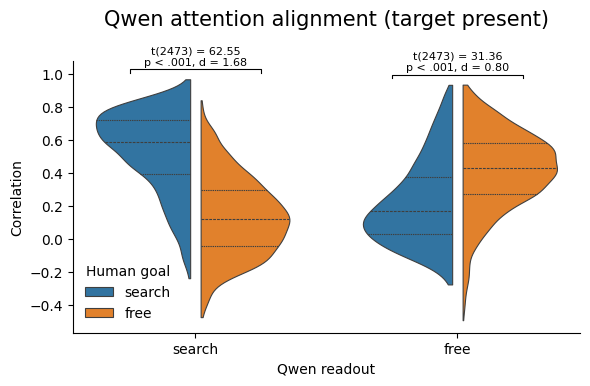

In [9]:
# Violin plot: per-picture correlations for each Qwen attention 2x2 cell.

model_readout_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(model_readout_order))

sns.violinplot(
    data=qwen_attention_correlations,
    x="qwen_readout",
    y="correlation",
    hue="human_goal",
    order=model_readout_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = qwen_attention_correlations["correlation"].max()
annotation_step = 0.05

for readout_index, model_readout in enumerate(model_readout_order):
    pairwise_row = qwen_attention_pairwise_tests[
        qwen_attention_pairwise_tests["qwen_readout"] == model_readout
    ].iloc[0]

    x_left = x_positions[readout_index] - 0.25
    x_right = x_positions[readout_index] + 0.25
    y_base = qwen_attention_correlations.loc[
        qwen_attention_correlations["qwen_readout"] == model_readout,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Qwen readout")
ax.set_ylabel("Correlation")
ax.set_title("Qwen attention alignment (target present)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
qwen_attention_violin_fig = fig

### Gemma / Attention Readout


In [10]:
# Gemma, target-present, attention arm: index saved attention maps.
gemma_attention_search_map_index = U.get_npz_paths("gemma", "tp", "search")
gemma_attention_free_map_index = U.get_npz_paths("gemma", "tp", "free")

print("Gemma TP attention search map files:", len(gemma_attention_search_map_index))
print("Gemma TP attention free map files:", len(gemma_attention_free_map_index))

Gemma TP attention search map files: 2476
Gemma TP attention free map files: 2476


In [11]:
# Compute long-format per-picture correlations from saved attention-map grids.
gemma_attention_search_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in gemma_attention_search_map_index.items()
}
gemma_attention_free_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in gemma_attention_free_map_index.items()
}

gemma_attention_correlation_rows = []
gemma_attention_shared_pictures = sorted(
    set(gemma_attention_search_density_maps)
    & set(gemma_attention_free_density_maps)
    & set(tp_human_search_density_maps)
    & set(tp_human_free_density_maps)
)

for target, name in gemma_attention_shared_pictures:
    map_pairs = [
        ("search", "search", gemma_attention_search_density_maps[(target, name)], tp_human_search_density_maps[(target, name)]),
        ("search", "free", gemma_attention_search_density_maps[(target, name)], tp_human_free_density_maps[(target, name)]),
        ("free", "search", gemma_attention_free_density_maps[(target, name)], tp_human_search_density_maps[(target, name)]),
        ("free", "free", gemma_attention_free_density_maps[(target, name)], tp_human_free_density_maps[(target, name)]),
    ]

    for model_readout, human_goal, model_map, human_map in map_pairs:
        correlation = gm.cc(model_map, human_map)
        if np.isfinite(correlation):
            gemma_attention_correlation_rows.append(
                {
                    "target": target,
                    "name": name,
                    "gemma_readout": model_readout,
                    "human_goal": human_goal,
                    "correlation": correlation,
                }
            )

gemma_attention_correlations = pd.DataFrame(gemma_attention_correlation_rows)
gemma_attention_correlations

,target,name,gemma_readout,human_goal,correlation
0,bottle,000000001455.jpg,search,search,0.630983
1,bottle,000000001455.jpg,search,free,0.011475
2,bottle,000000001455.jpg,free,search,-0.140045
3,bottle,000000001455.jpg,free,free,0.270025
4,bottle,000000009527.jpg,search,search,0.722438
...,...,...,...,...,...
9891,tv,000000579186.jpg,free,free,0.061830
9892,tv,000000580392.jpg,search,search,0.549529
9893,tv,000000580392.jpg,search,free,-0.092785
9894,tv,000000580392.jpg,free,search,-0.026858


In [12]:
# Mean and SD for each target-present Gemma attention 2x2 cell.
gemma_attention_correlations.groupby(["gemma_readout", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,gemma_readout,human_goal,mean,std
0,free,free,0.134068,0.201708
1,free,search,-0.003740,0.168403
2,search,free,0.068082,0.195508
3,search,search,0.627887,0.169517


In [13]:
# Repeated-measures ANOVA for the Gemma target-present attention 2x2 design.
gemma_attention_anova_data = gemma_attention_correlations.copy()
gemma_attention_anova_data["picture"] = (
    gemma_attention_anova_data["target"] + " / " + gemma_attention_anova_data["name"]
)

gemma_attention_rmanova = pg.rm_anova(
    data=gemma_attention_anova_data,
    dv="correlation",
    within=["gemma_readout", "human_goal"],
    subject="picture",
    detailed=True,
)

gemma_attention_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,gemma_readout,197.888894,1,2473,197.888894,5519.361569,0.0,0.0,0.370419,1.0
1,human_goal,110.143276,1,2473,110.143276,5395.842148,0.0,0.0,0.246690,1.0
2,gemma_readout * human_goal,301.000915,1,2473,301.000915,9004.394313,0.0,0.0,0.472275,1.0


In [14]:
# Pairwise tests: compare human_goal within each Gemma target-present attention readout.
gemma_attention_pairwise_results = []

for model_readout, readout_data in gemma_attention_anova_data.groupby("gemma_readout", sort=False):
    paired_goals = (
        readout_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    gemma_attention_pairwise_results.append(
        {
            "gemma_readout": model_readout,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

gemma_attention_pairwise_tests = pd.DataFrame(gemma_attention_pairwise_results)
gemma_attention_pairwise_tests[
    ["gemma_readout", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,gemma_readout,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,120.465464,2473,two-sided,0.000000e+00,3.059464,0.551,0.569
1,free,search,free,-29.427140,2473,two-sided,1.882540e-163,0.741686,-0.147,-0.129


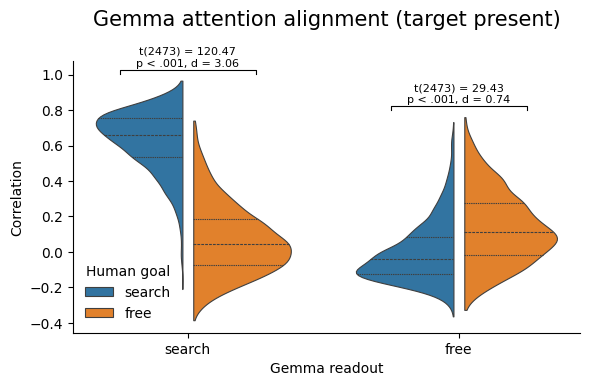

In [15]:
# Violin plot: per-picture correlations for each Gemma attention 2x2 cell.

model_readout_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(model_readout_order))

sns.violinplot(
    data=gemma_attention_correlations,
    x="gemma_readout",
    y="correlation",
    hue="human_goal",
    order=model_readout_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = gemma_attention_correlations["correlation"].max()
annotation_step = 0.05

for readout_index, model_readout in enumerate(model_readout_order):
    pairwise_row = gemma_attention_pairwise_tests[
        gemma_attention_pairwise_tests["gemma_readout"] == model_readout
    ].iloc[0]

    x_left = x_positions[readout_index] - 0.25
    x_right = x_positions[readout_index] + 0.25
    y_base = gemma_attention_correlations.loc[
        gemma_attention_correlations["gemma_readout"] == model_readout,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Gemma readout")
ax.set_ylabel("Correlation")
ax.set_title("Gemma attention alignment (target present)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
gemma_attention_violin_fig = fig

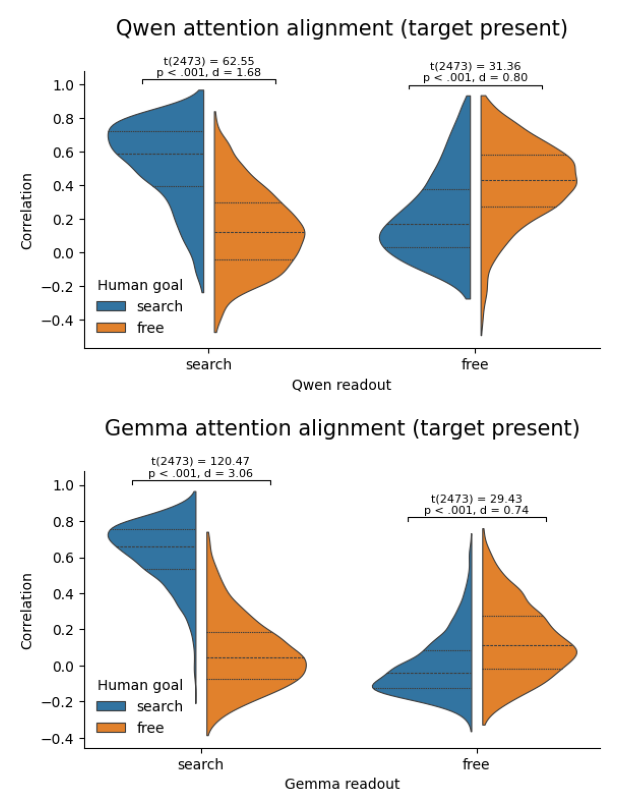

In [16]:
# Stack the already-created target-present Qwen and Gemma attention violin figures into one image.
from io import BytesIO


def figure_to_image(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, bbox_inches="tight")
    buffer.seek(0)
    return np.asarray(Image.open(buffer).convert("RGB"))


qwen_attention_violin_image = figure_to_image(qwen_attention_violin_fig)
gemma_attention_violin_image = figure_to_image(gemma_attention_violin_fig)

fig, axes = plt.subplots(2, 1, figsize=(6, 8))

for ax, image in zip(
    axes,
    [qwen_attention_violin_image, gemma_attention_violin_image],
):
    ax.imshow(image)
    ax.axis("off")

fig.tight_layout(pad=0)


In [17]:
# Helper for final attention-map visualizations.
def plot_attention_example(condition, picture, original_title):
    """Plot original image plus human/model search and free attention maps."""
    image_folder = "TP-images" if condition == "tp" else "TA-images"
    target, name = picture
    example_image_path = (
        ANALYSIS.parent
        / "data"
        / "COCO-Search18"
        / image_folder
        / target
        / name
    )
    example_image = Image.open(example_image_path).convert("RGB")
    example_image, _, _ = gm.crop_letterbox(example_image)

    human_fixations = U.load_fixations(
        U.get_run_ids("qwen-thinking", condition, "output", "search"),
        mode="human",
    )
    human_search_maps = U.density_maps_from_points(
        human_fixations,
        mode="human",
        goal="search",
    )
    human_free_maps = U.density_maps_from_points(
        human_fixations,
        mode="human",
        goal="free",
    )
    qwen_search_maps = U.get_npz_paths("qwen-thinking", condition, "search")
    qwen_free_maps = U.get_npz_paths("qwen-thinking", condition, "free")
    gemma_search_maps = U.get_npz_paths("gemma", condition, "search")
    gemma_free_maps = U.get_npz_paths("gemma", condition, "free")

    example_maps = [
        ("Human search", human_search_maps[picture]),
        ("Qwen search", U.density_map_from_attention(qwen_search_maps[picture])),
        ("Gemma search", U.density_map_from_attention(gemma_search_maps[picture])),
        ("Human free", human_free_maps[picture]),
        ("Qwen free", U.density_map_from_attention(qwen_free_maps[picture])),
        ("Gemma free", U.density_map_from_attention(gemma_free_maps[picture])),
    ]

    fig = plt.figure(figsize=(14, 5), constrained_layout=True)
    grid = fig.add_gridspec(
        2,
        4,
        width_ratios=[1.4, 1, 1, 1],
        wspace=0,
        hspace=0,
    )

    original_ax = fig.add_subplot(grid[:, 0])
    original_ax.imshow(example_image)
    original_ax.set_title(original_title, fontsize=15)
    original_ax.axis("off")

    axes = [fig.add_subplot(grid[row, col]) for row in range(2) for col in range(1, 4)]

    for ax, (title, density) in zip(axes, example_maps):
        plot_image = example_image.resize((density.shape[1], density.shape[0]))

        ax.imshow(plot_image, alpha=1)
        ax.imshow(density, cmap="magma", vmin=0, vmax=1, alpha=0.6)
        ax.set_title(title, fontsize=15)
        ax.axis("off")

    return fig, axes

(<Figure size 1400x500 with 7 Axes>,
 [<Axes: title={'center': 'Human search'}>,
  <Axes: title={'center': 'Qwen search'}>,
  <Axes: title={'center': 'Gemma search'}>,
  <Axes: title={'center': 'Human free'}>,
  <Axes: title={'center': 'Qwen free'}>,
  <Axes: title={'center': 'Gemma free'}>])

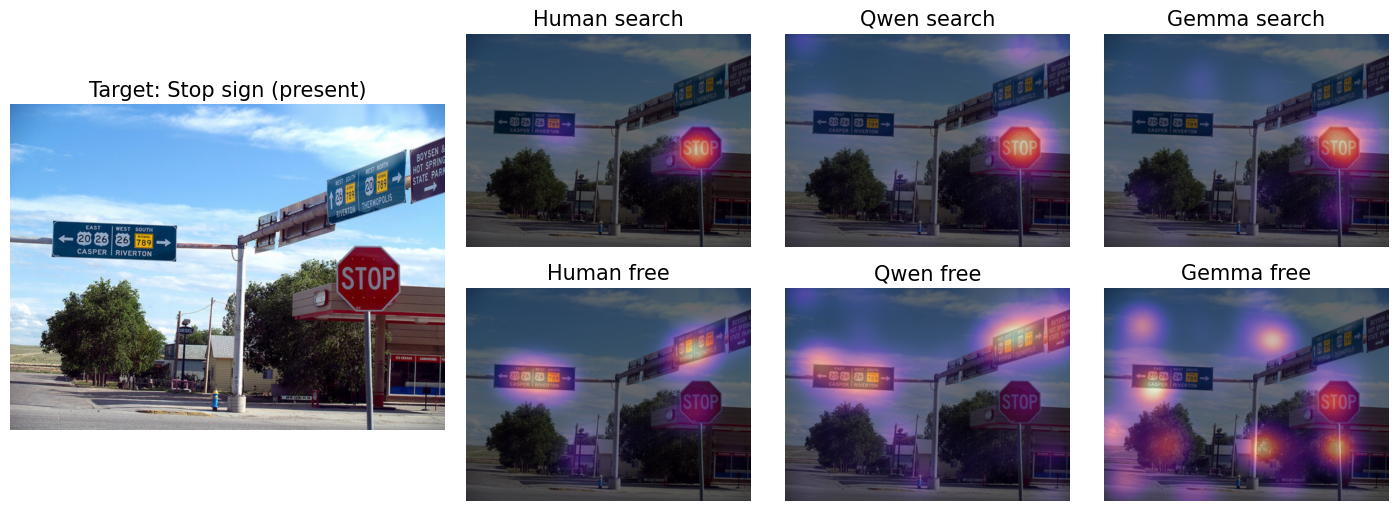

In [18]:
# Plot one representative target-present image's attention maps.
tp_example_picture = ("stop sign", "000000493682.jpg")
plot_attention_example(
    condition="tp",
    picture=tp_example_picture,
    original_title="Target: Stop sign (present)",
)

## Target-Absent Images


In [19]:
# Locate the target-absent attention run IDs used for each model and readout.
ta_attention_runs = []

for model in MODELS:
    for readout in ["search", "free"]:
        runs = U.get_run_ids(model, condition="ta", readout="attention", goal=readout)
        ta_attention_runs.append(
            {
                "model": model,
                "condition": "ta",
                "readout": "attention",
                "goal": readout,
                "runs": runs,
            }
        )

pd.DataFrame(ta_attention_runs)

,model,condition,readout,goal,runs
0,qwen-thinking,ta,attention,search,"[58031823, 58309304]"
1,qwen-thinking,ta,attention,free,"[58648156, 58648157]"
2,gemma,ta,attention,search,"[57251466, 58380381]"
3,gemma,ta,attention,free,"[58648160, 58648161]"


### Qwen / Attention Readout


In [20]:
# Qwen, target-absent, attention arm: index saved attention maps and human fixations.
qwen_ta_attention_search_map_index = U.get_npz_paths("qwen-thinking", "ta", "search")
qwen_ta_attention_free_map_index = U.get_npz_paths("qwen-thinking", "ta", "free")
ta_human_fixations = U.load_fixations(
    U.get_run_ids("qwen-thinking", "ta", "output", "search"),
    mode="human",
)

print("Qwen TA attention search map files:", len(qwen_ta_attention_search_map_index))
print("Qwen TA attention free map files:", len(qwen_ta_attention_free_map_index))
print("TA human fixation rows:", len(ta_human_fixations))

Qwen TA attention search map files: 2416
Qwen TA attention free map files: 2416
TA human fixation rows: 456037


In [21]:
# Compute long-format per-picture correlations from saved attention-map grids.
# Downscale both attention and human maps by 4 for the correlation calculation.
ta_human_search_density_maps = U.density_maps_from_points(
    ta_human_fixations,
    mode="human",
    goal="search",
)
ta_human_free_density_maps = U.density_maps_from_points(
    ta_human_fixations,
    mode="human",
    goal="free",
)
qwen_ta_attention_search_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in qwen_ta_attention_search_map_index.items()
}
qwen_ta_attention_free_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in qwen_ta_attention_free_map_index.items()
}

qwen_ta_attention_correlation_rows = []
qwen_ta_attention_shared_pictures = sorted(
    set(qwen_ta_attention_search_density_maps)
    & set(qwen_ta_attention_free_density_maps)
    & set(ta_human_search_density_maps)
    & set(ta_human_free_density_maps)
)

for target, name in qwen_ta_attention_shared_pictures:
    map_pairs = [
        ("search", "search", qwen_ta_attention_search_density_maps[(target, name)], ta_human_search_density_maps[(target, name)]),
        ("search", "free", qwen_ta_attention_search_density_maps[(target, name)], ta_human_free_density_maps[(target, name)]),
        ("free", "search", qwen_ta_attention_free_density_maps[(target, name)], ta_human_search_density_maps[(target, name)]),
        ("free", "free", qwen_ta_attention_free_density_maps[(target, name)], ta_human_free_density_maps[(target, name)]),
    ]

    for model_readout, human_goal, model_map, human_map in map_pairs:
        correlation = gm.cc(model_map, human_map)
        if np.isfinite(correlation):
            qwen_ta_attention_correlation_rows.append(
                {
                    "target": target,
                    "name": name,
                    "qwen_readout": model_readout,
                    "human_goal": human_goal,
                    "correlation": correlation,
                }
            )

qwen_ta_attention_correlations = pd.DataFrame(qwen_ta_attention_correlation_rows)
qwen_ta_attention_correlations

,target,name,qwen_readout,human_goal,correlation
0,bottle,000000000196.jpg,search,search,0.112983
1,bottle,000000000196.jpg,search,free,-0.104206
2,bottle,000000000196.jpg,free,search,0.367408
3,bottle,000000000196.jpg,free,free,0.206705
4,bottle,000000003992.jpg,search,search,0.332349
...,...,...,...,...,...
9647,tv,000000578553.jpg,free,free,0.578549
9648,tv,000000578775.jpg,search,search,0.487495
9649,tv,000000578775.jpg,search,free,0.182673
9650,tv,000000578775.jpg,free,search,0.301486


In [22]:
# Mean and SD for each target-absent Qwen attention 2x2 cell.
qwen_ta_attention_correlations.groupby(["qwen_readout", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,qwen_readout,human_goal,mean,std
0,free,free,0.419361,0.241157
1,free,search,0.289367,0.216660
2,search,free,0.146460,0.257935
3,search,search,0.205958,0.247022


In [23]:
# Repeated-measures ANOVA for the Qwen target-absent attention 2x2 design.
qwen_ta_attention_anova_data = qwen_ta_attention_correlations.copy()
qwen_ta_attention_anova_data["picture"] = (
    qwen_ta_attention_anova_data["target"] + " / " + qwen_ta_attention_anova_data["name"]
)

qwen_ta_attention_rmanova = pg.rm_anova(
    data=qwen_ta_attention_anova_data,
    dv="correlation",
    within=["qwen_readout", "human_goal"],
    subject="picture",
    detailed=True,
)

qwen_ta_attention_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,qwen_readout,76.586438,1,2412,76.586438,1825.180209,1.930184e-297,1.930184e-297,0.120091,1.0
1,human_goal,2.997922,1,2412,2.997922,67.824568,2.893328e-16,2.893328e-16,0.005314,1.0
2,qwen_readout * human_goal,21.660770,1,2412,21.660770,1317.710767,1.390264e-230,1.390264e-230,0.037166,1.0


In [24]:
# Pairwise tests: compare human_goal within each Qwen target-absent attention readout.
qwen_ta_attention_pairwise_results = []

for model_readout, readout_data in qwen_ta_attention_anova_data.groupby("qwen_readout", sort=False):
    paired_goals = (
        readout_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    qwen_ta_attention_pairwise_results.append(
        {
            "qwen_readout": model_readout,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

qwen_ta_attention_pairwise_tests = pd.DataFrame(qwen_ta_attention_pairwise_results)
qwen_ta_attention_pairwise_tests[
    ["qwen_readout", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,qwen_readout,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,11.665896,2412,two-sided,1.244925e-30,0.235600,0.049,0.069
1,free,search,free,-26.398102,2412,two-sided,4.025989e-135,0.567071,-0.140,-0.120


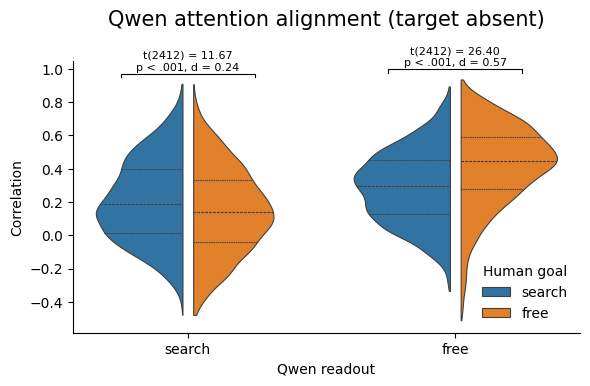

In [25]:
# Violin plot: per-picture correlations for each Qwen attention 2x2 cell.

model_readout_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(model_readout_order))

sns.violinplot(
    data=qwen_ta_attention_correlations,
    x="qwen_readout",
    y="correlation",
    hue="human_goal",
    order=model_readout_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = qwen_ta_attention_correlations["correlation"].max()
annotation_step = 0.05

for readout_index, model_readout in enumerate(model_readout_order):
    pairwise_row = qwen_ta_attention_pairwise_tests[
        qwen_ta_attention_pairwise_tests["qwen_readout"] == model_readout
    ].iloc[0]

    x_left = x_positions[readout_index] - 0.25
    x_right = x_positions[readout_index] + 0.25
    y_base = qwen_ta_attention_correlations.loc[
        qwen_ta_attention_correlations["qwen_readout"] == model_readout,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Qwen readout")
ax.set_ylabel("Correlation")
ax.set_title("Qwen attention alignment (target absent)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
qwen_ta_attention_violin_fig = fig

### Gemma / Attention Readout


In [26]:
# Gemma, target-absent, attention arm: index saved attention maps.
gemma_ta_attention_search_map_index = U.get_npz_paths("gemma", "ta", "search")
gemma_ta_attention_free_map_index = U.get_npz_paths("gemma", "ta", "free")

print("Gemma TA attention search map files:", len(gemma_ta_attention_search_map_index))
print("Gemma TA attention free map files:", len(gemma_ta_attention_free_map_index))

Gemma TA attention search map files: 2416
Gemma TA attention free map files: 2416


In [27]:
# Compute long-format per-picture correlations from saved attention-map grids.
gemma_ta_attention_search_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in gemma_ta_attention_search_map_index.items()
}
gemma_ta_attention_free_density_maps = {
    image: U.density_map_from_attention(map_path)
    for image, map_path in gemma_ta_attention_free_map_index.items()
}

gemma_ta_attention_correlation_rows = []
gemma_ta_attention_shared_pictures = sorted(
    set(gemma_ta_attention_search_density_maps)
    & set(gemma_ta_attention_free_density_maps)
    & set(ta_human_search_density_maps)
    & set(ta_human_free_density_maps)
)

for target, name in gemma_ta_attention_shared_pictures:
    map_pairs = [
        ("search", "search", gemma_ta_attention_search_density_maps[(target, name)], ta_human_search_density_maps[(target, name)]),
        ("search", "free", gemma_ta_attention_search_density_maps[(target, name)], ta_human_free_density_maps[(target, name)]),
        ("free", "search", gemma_ta_attention_free_density_maps[(target, name)], ta_human_search_density_maps[(target, name)]),
        ("free", "free", gemma_ta_attention_free_density_maps[(target, name)], ta_human_free_density_maps[(target, name)]),
    ]

    for model_readout, human_goal, model_map, human_map in map_pairs:
        correlation = gm.cc(model_map, human_map)
        if np.isfinite(correlation):
            gemma_ta_attention_correlation_rows.append(
                {
                    "target": target,
                    "name": name,
                    "gemma_readout": model_readout,
                    "human_goal": human_goal,
                    "correlation": correlation,
                }
            )

gemma_ta_attention_correlations = pd.DataFrame(gemma_ta_attention_correlation_rows)
gemma_ta_attention_correlations

,target,name,gemma_readout,human_goal,correlation
0,bottle,000000000196.jpg,search,search,-0.181682
1,bottle,000000000196.jpg,search,free,-0.251941
2,bottle,000000000196.jpg,free,search,0.063984
3,bottle,000000000196.jpg,free,free,0.226402
4,bottle,000000003992.jpg,search,search,0.035406
...,...,...,...,...,...
9647,tv,000000578553.jpg,free,free,0.417342
9648,tv,000000578775.jpg,search,search,-0.089460
9649,tv,000000578775.jpg,search,free,0.013353
9650,tv,000000578775.jpg,free,search,-0.012137


In [28]:
# Mean and SD for each target-absent Gemma attention 2x2 cell.
gemma_ta_attention_correlations.groupby(["gemma_readout", "human_goal"])["correlation"].agg(["mean", "std"]).reset_index()

,gemma_readout,human_goal,mean,std
0,free,free,0.125889,0.200955
1,free,search,-0.013397,0.171291
2,search,free,0.027509,0.207481
3,search,search,0.151410,0.228178


In [29]:
# Repeated-measures ANOVA for the Gemma target-absent attention 2x2 design.
gemma_ta_attention_anova_data = gemma_ta_attention_correlations.copy()
gemma_ta_attention_anova_data["picture"] = (
    gemma_ta_attention_anova_data["target"] + " / " + gemma_ta_attention_anova_data["name"]
)

gemma_ta_attention_rmanova = pg.rm_anova(
    data=gemma_ta_attention_anova_data,
    dv="correlation",
    within=["gemma_readout", "human_goal"],
    subject="picture",
    detailed=True,
)

gemma_ta_attention_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,gemma_readout,2.661936,1,2412,2.661936,48.999415,3.305739e-12,3.305739e-12,0.006651,1.0
1,human_goal,0.142784,1,2412,0.142784,7.545247,6.061566e-03,6.061566e-03,0.000359,1.0
2,gemma_readout * human_goal,41.785284,1,2412,41.785284,2022.727325,2.549379e-321,2.549379e-321,0.095102,1.0


In [30]:
# Pairwise tests: compare human_goal within each Gemma target-absent attention readout.
gemma_ta_attention_pairwise_results = []

for model_readout, readout_data in gemma_ta_attention_anova_data.groupby("gemma_readout", sort=False):
    paired_goals = (
        readout_data
        .pivot(index="picture", columns="human_goal", values="correlation")
        .dropna(subset=["search", "free"])
    )
    difference = paired_goals["search"] - paired_goals["free"]
    test = pg.ttest(paired_goals["search"], paired_goals["free"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    gemma_ta_attention_pairwise_results.append(
        {
            "gemma_readout": model_readout,
            "A": "search",
            "B": "free",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

gemma_ta_attention_pairwise_tests = pd.DataFrame(gemma_ta_attention_pairwise_results)
gemma_ta_attention_pairwise_tests[
    ["gemma_readout", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,gemma_readout,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,search,search,free,29.554927,2412,two-sided,4.212514e-164,0.568156,0.116,0.132
1,free,search,free,-35.688161,2412,two-sided,2.359752e-224,0.745986,-0.147,-0.132


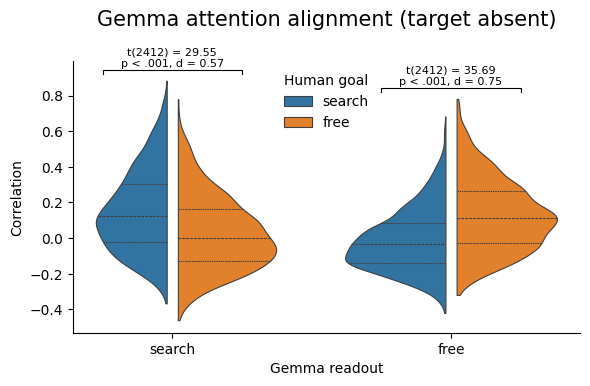

In [31]:
# Violin plot: per-picture correlations for each Gemma attention 2x2 cell.

model_readout_order = ["search", "free"]
human_goal_order = ["search", "free"]

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(model_readout_order))

sns.violinplot(
    data=gemma_ta_attention_correlations,
    x="gemma_readout",
    y="correlation",
    hue="human_goal",
    order=model_readout_order,
    hue_order=human_goal_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = gemma_ta_attention_correlations["correlation"].max()
annotation_step = 0.05

for readout_index, model_readout in enumerate(model_readout_order):
    pairwise_row = gemma_ta_attention_pairwise_tests[
        gemma_ta_attention_pairwise_tests["gemma_readout"] == model_readout
    ].iloc[0]

    x_left = x_positions[readout_index] - 0.25
    x_right = x_positions[readout_index] + 0.25
    y_base = gemma_ta_attention_correlations.loc[
        gemma_ta_attention_correlations["gemma_readout"] == model_readout,
        "correlation",
    ].max() + 0.04
    y_top = y_base + 0.02

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.01,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xlabel("Gemma readout")
ax.set_ylabel("Correlation")
ax.set_title("Gemma attention alignment (target absent)", y=1.1, fontsize=15)
ax.set_ylim(top=annotation_top)
ax.legend(title="Human goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
gemma_ta_attention_violin_fig = fig

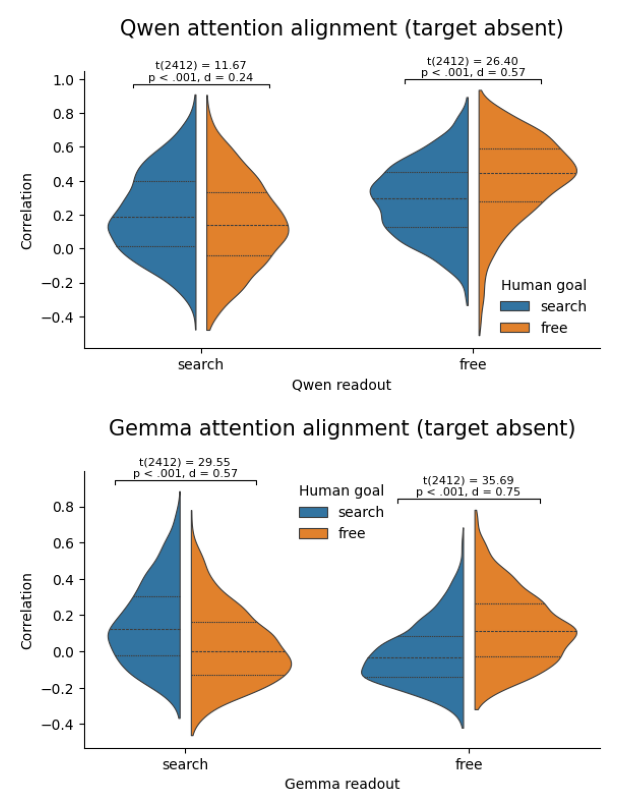

In [32]:
# Stack the already-created target-absent Qwen and Gemma attention violin figures into one image.
from io import BytesIO


def figure_to_image(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, bbox_inches="tight")
    buffer.seek(0)
    return np.asarray(Image.open(buffer).convert("RGB"))


qwen_ta_attention_violin_image = figure_to_image(qwen_ta_attention_violin_fig)
gemma_ta_attention_violin_image = figure_to_image(gemma_ta_attention_violin_fig)

fig, axes = plt.subplots(2, 1, figsize=(6, 8))

for ax, image in zip(
    axes,
    [qwen_ta_attention_violin_image, gemma_ta_attention_violin_image],
):
    ax.imshow(image)
    ax.axis("off")

fig.tight_layout(pad=0)


(<Figure size 1400x500 with 7 Axes>,
 [<Axes: title={'center': 'Human search'}>,
  <Axes: title={'center': 'Qwen search'}>,
  <Axes: title={'center': 'Gemma search'}>,
  <Axes: title={'center': 'Human free'}>,
  <Axes: title={'center': 'Qwen free'}>,
  <Axes: title={'center': 'Gemma free'}>])

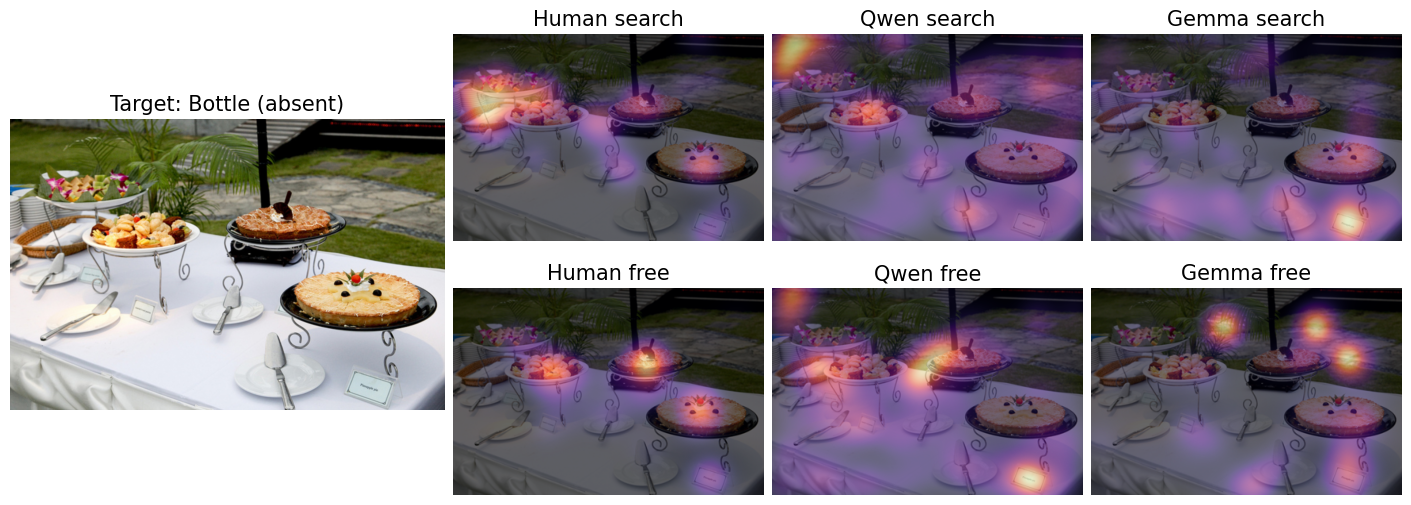

In [35]:
# Plot one representative target-absent image's attention maps.
ta_example_picture =  ("bottle", "000000085462.jpg")
plot_attention_example(
    condition="ta",
    picture=ta_example_picture,
    original_title="Target: Bottle (absent)",
)